IA Explicable (XAI) - Feature Importance
==========================================
Ejemplo: ¿qué variables influyen más en el PRECIO de una casa?

Dataset público: California Housing (incluido en scikit-learn).
Cada fila es un grupo de casas (bloque censal) en California.
Objetivo: predecir el valor medio de las casas (en cientos de miles de USD).


In [1]:
# 1. Librerías
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 2. Cargar dataset
data = fetch_california_housing()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

In [3]:
X.isna().sum()
X.shape

(20640, 8)

In [4]:
# 3. Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
# 4. Entrenar Random Forest
model = RandomForestRegressor(n_estimators=100,random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

1.   MedInc → Ingreso medio de los hogares del área.
2.   AveOccup → Número promedio de personas por vivienda.
3.   Latitude → Latitud geográfica del área.
4. Longitude → Longitud geográfica del área.
5. HouseAge → Edad promedio de las viviendas.
6. AveRooms → Número promedio de habitaciones por vivienda.
7. Population → Población del área.
8. AveBedrms → Número promedio de dormitorios por vivienda.

In [6]:
# 5. Feature Importance con Metodo Nativo del MODELO
model.feature_importances_

array([0.52487148, 0.05459322, 0.04427185, 0.02960631, 0.03064978,
       0.13844281, 0.08893574, 0.08862881])

In [7]:
X.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='object')

In [8]:
#Hago una Serie de las importancias
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
# index=X.columns alinea cada importance con el nombre de su feature
print(importance)
importance.shape

MedInc        0.524871
AveOccup      0.138443
Latitude      0.088936
Longitude     0.088629
HouseAge      0.054593
AveRooms      0.044272
Population    0.030650
AveBedrms     0.029606
dtype: float64


(8,)

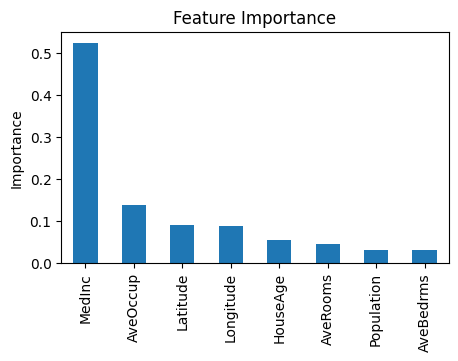

In [9]:
# 6. Gráfico
plt.figure(figsize=(5, 3))
importance.plot(kind="bar")
plt.title("Feature Importance")
plt.ylabel("Importance")
plt.show()

In [10]:
# 7. Feature Importance con funcion "permutation_importance"
# Despues del Paso #4
result = permutation_importance(model, X_test, y_test, random_state=42, n_repeats=7)
result

{'importances_mean': array([0.72948508, 0.07074767, 0.02889177, 0.00916519, 0.00764602,
        0.20362566, 0.44007179, 0.33354156]),
 'importances_std': array([0.00887222, 0.00445727, 0.00191725, 0.00146459, 0.00066274,
        0.00477243, 0.0053791 , 0.00709965]),
 'importances': array([[0.74117293, 0.72970471, 0.72182119, 0.72763734, 0.7134624 ,
         0.73514979, 0.7374472 ],
        [0.0725686 , 0.06651323, 0.06589799, 0.07673565, 0.06501641,
         0.07497777, 0.07352403],
        [0.0301236 , 0.03079328, 0.03072602, 0.02547641, 0.0294226 ,
         0.02660181, 0.02909871],
        [0.00895723, 0.00783987, 0.01209981, 0.00881141, 0.00813379,
         0.00785052, 0.01046371],
        [0.00759163, 0.0077066 , 0.00811307, 0.00772112, 0.00829755,
         0.00612418, 0.00796799],
        [0.19973399, 0.20332179, 0.20192276, 0.20794705, 0.19617838,
         0.20450187, 0.21177375],
        [0.43514797, 0.43543641, 0.45106661, 0.44126361, 0.44163687,
         0.44138637, 0.43456469

In [11]:
#Hago una Serie de las importancias
importance = pd.Series(result.importances_mean, index=X.columns).sort_values(ascending=False)
importance

,0
MedInc,0.729485
Latitude,0.440072
Longitude,0.333542
AveOccup,0.203626
HouseAge,0.070748
AveRooms,0.028892
AveBedrms,0.009165
Population,0.007646


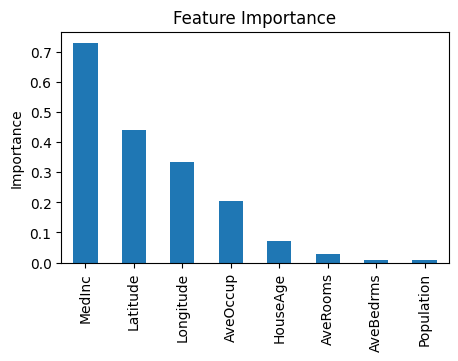

In [12]:
# 8. Gráfico
plt.figure(figsize=(5, 3))
importance.plot(kind="bar")
plt.title("Feature Importance")
plt.ylabel("Importance")
plt.show()

**Permutation_importance** no revuelve cada columna una sola vez, la revuelve varias veces, por defecto 5 veces. Es más lento, pero más confiable porque mide el efecto real sobre las predicciones, no solo cómo se construyó el árbol.

**modelo.feature_importances_**
Se calcula durante el entrenamiento, mirando internamente los árboles.
Mide cuánto ayudó cada variable a "dividir mejor" los datos dentro del árbol. No cuesta nada extra, el modelo ya lo tiene.